In [24]:
import pyvrp
# fmt: off
COORDS = [
    (456, 320),  # location 0 - the depot
    (228, 0),    # location 1
    (912, 0),    # location 2
    (0, 80),     # location 3
    (114, 80),   # location 4
    (570, 160),  # location 5
    (798, 160),  # location 6
    (342, 240),  # location 7
    (684, 240),  # location 8
    (570, 400),  # location 9
    (912, 400),  # location 10
    (114, 480),  # location 11
    (228, 480),  # location 12
    (342, 560),  # location 13
    (684, 560),  # location 14
    (0, 640),    # location 15
    (798, 640),  # location 16
]
DEMANDS = [0, 1, 1, 2, 4, 2, 4, 8, 8, 1, 2, 1, 2, 4, 4, 8, 8]
# fmt: on

In [2]:
sum(DEMANDS)

60

In [3]:
from pyvrp import Model

m = Model()
m.add_vehicle_type(4, capacity=15)
depot = m.add_depot(x=COORDS[0][0], y=COORDS[0][1])
clients = [
    m.add_client(x=COORDS[idx][0], y=COORDS[idx][1], delivery=DEMANDS[idx])
    for idx in range(1, len(COORDS))
]

for frm in m.locations:
    for to in m.locations:
        distance = abs(frm.x - to.x) + abs(frm.y - to.y)  # Manhattan
        m.add_edge(frm, to, distance=distance)

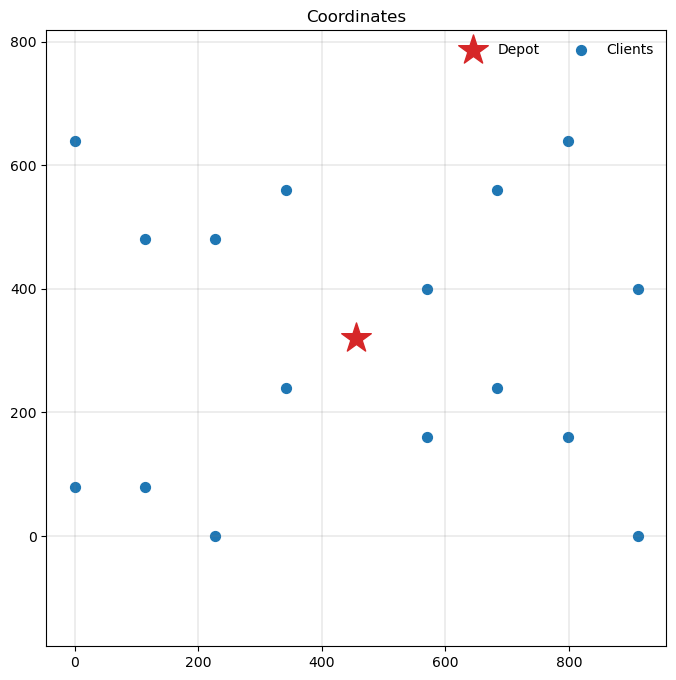

In [4]:

import matplotlib.pyplot as plt

from pyvrp.plotting import plot_coordinates, plot_solution, plot_diversity, plot_objectives, plot_runtimes

_, ax = plt.subplots(figsize=(8, 8))
plot_coordinates(m.data(), ax=ax)


In [ ]:
from pyvrp.stop import MaxRuntime

res = m.solve(stop=MaxRuntime(2), display=True)  # un segundo



PyVRP v0.11.3

Solving an instance with:
    1 depot
    16 clients
    4 vehicles (1 vehicle type)

                  |       Feasible        |      Infeasible
    Iters    Time |   #      Avg     Best |   #      Avg     Best
H     500      1s |  45     6230     6208 |  39     6995     5905
     1000      2s |  46     6219     6208 |  65     6198     5235

Search terminated in 2.00s after 1135 iterations.
Best-found solution has cost 6208.

Solution results
    # routes: 4
     # trips: 4
   # clients: 16
   objective: 6208
    distance: 6208
    duration: 0
# iterations: 1135
    run-time: 2.00 seconds



In [ ]:
print (res) #Imprime solucion

Solution results
    # routes: 4
     # trips: 4
   # clients: 16
   objective: 6208
    distance: 6208
    duration: 0
# iterations: 1135
    run-time: 2.00 seconds

Routes
------
Route #1: 7 1 4 3
Route #2: 14 16 10 9
Route #3: 5 6 2 8
Route #4: 13 15 11 12



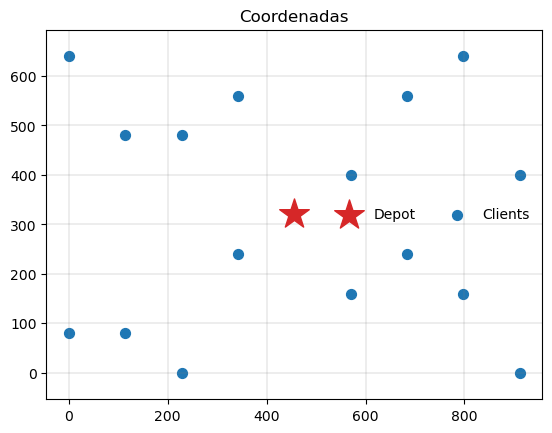

In [7]:
plot_coordinates(data=m.data(),title='Coordenadas') #Gráfica de coordenadas

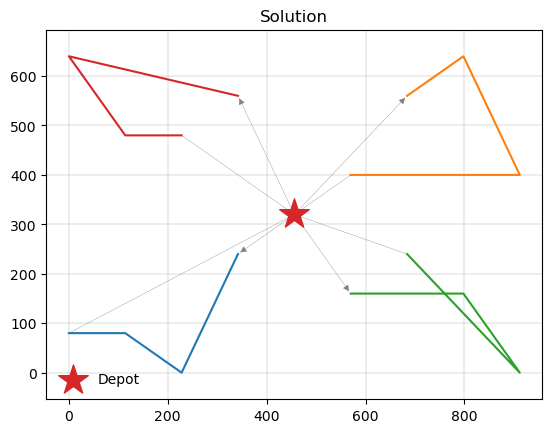

In [8]:
plot_solution(res.best, data=m.data()) #Gráfica de rutas

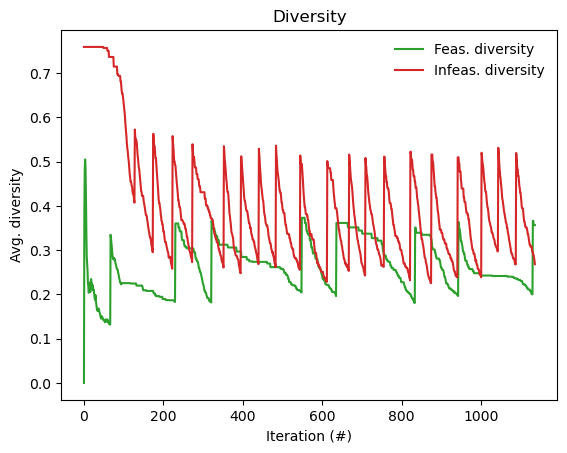

In [9]:
plot_diversity(res) #Gráfico de Diversidad 

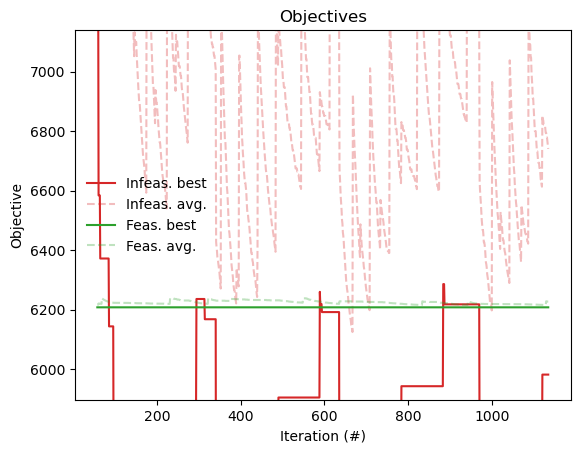

In [10]:
plot_objectives(res) #Gráfico de Función Objetivo

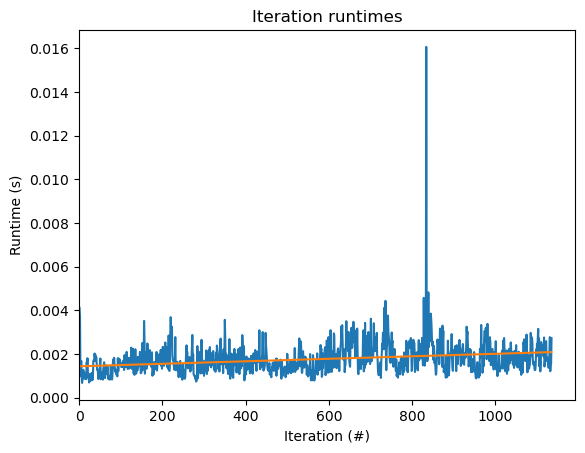

In [11]:
plot_runtimes(res) #Gráfico de tiempos de ejecución

In [17]:
sol=res.best
rutas=sol.routes

In [ ]:
sol.has_excess_distance()#dice si la solucion tiene exceso de distancia

False

In [ ]:
sol.num_routes()#numero de rutas de la solucion

4

In [ ]:
rutas=sol.routes()#lista de rutas de las solucion

In [ ]:
rutas[0].vehicle_type()#que tipo de vehiculo usa la primera ruta de la solucion

0

In [ ]:
rutas[0].visits() #que nodos visita el vehiculo en la primera ruta de la solucion

[7, 1, 4, 3]